In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('all.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36707 entries, 0 to 36706
Data columns (total 80 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Querylength                      36707 non-null  int64  
 1   domain_token_count               36707 non-null  int64  
 2   path_token_count                 36707 non-null  int64  
 3   avgdomaintokenlen                36707 non-null  float64
 4   longdomaintokenlen               36707 non-null  int64  
 5   avgpathtokenlen                  36427 non-null  float64
 6   tld                              36707 non-null  int64  
 7   charcompvowels                   36707 non-null  int64  
 8   charcompace                      36707 non-null  int64  
 9   ldl_url                          36707 non-null  int64  
 10  ldl_domain                       36707 non-null  int64  
 11  ldl_path                         36707 non-null  int64  
 12  ldl_filename      

In [4]:
df.columns

Index(['Querylength', 'domain_token_count', 'path_token_count',
       'avgdomaintokenlen', 'longdomaintokenlen', 'avgpathtokenlen', 'tld',
       'charcompvowels', 'charcompace', 'ldl_url', 'ldl_domain', 'ldl_path',
       'ldl_filename', 'ldl_getArg', 'dld_url', 'dld_domain', 'dld_path',
       'dld_filename', 'dld_getArg', 'urlLen', 'domainlength', 'pathLength',
       'subDirLen', 'fileNameLen', 'this.fileExtLen', 'ArgLen', 'pathurlRatio',
       'ArgUrlRatio', 'argDomanRatio', 'domainUrlRatio', 'pathDomainRatio',
       'argPathRatio', 'executable', 'isPortEighty', 'NumberofDotsinURL',
       'ISIpAddressInDomainName', 'CharacterContinuityRate',
       'LongestVariableValue', 'URL_DigitCount', 'host_DigitCount',
       'Directory_DigitCount', 'File_name_DigitCount', 'Extension_DigitCount',
       'Query_DigitCount', 'URL_Letter_Count', 'host_letter_count',
       'Directory_LetterCount', 'Filename_LetterCount',
       'Extension_LetterCount', 'Query_LetterCount', 'LongestPathToken

In [5]:
domain_col = [
    'domain_token_count', 'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'domainlength', 'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain', 
    'URL_Type_obf_Type'
]

In [6]:
select_df = df[domain_col]

In [7]:
select_df.isnull().sum()

domain_token_count          0
avgdomaintokenlen           0
longdomaintokenlen          0
ldl_domain                  0
dld_domain                  0
domainlength                0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [8]:
(select_df==-1).sum()

domain_token_count          0
avgdomaintokenlen           0
longdomaintokenlen          0
ldl_domain                  0
dld_domain                  0
domainlength                0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [9]:
vif_col = [
    'domain_token_count', 'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'domainlength', 'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

In [10]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[vif_col]

# 결측치 무한값 리리
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# 스케일링 (표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# VIF 
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])]

# 출력
print(vif_df.sort_values(by='VIF', ascending=False))

                     Feature            VIF
5               domainlength  154053.106643
7          host_letter_count  120977.183444
6            host_DigitCount    7785.513910
0         domain_token_count    2556.148547
9           delimeter_Domain     556.759731
10        SymbolCount_Domain     387.368245
1          avgdomaintokenlen      13.014765
2         longdomaintokenlen      12.327581
8   Domain_LongestWordLength       8.656986
3                 ldl_domain       4.985270
4                 dld_domain       2.771247
11            Entropy_Domain       1.638577


In [11]:
# 상관계수 계산
corr_matrix = X.corr()  # 피어슨 상관계수 기본
print(corr_matrix)

                          domain_token_count  avgdomaintokenlen  \
domain_token_count                  1.000000          -0.212984   
avgdomaintokenlen                  -0.212984           1.000000   
longdomaintokenlen                  0.068065           0.895807   
ldl_domain                          0.197289           0.089185   
dld_domain                          0.120969           0.116432   
domainlength                        0.591225           0.603367   
host_DigitCount                     0.189512          -0.015315   
host_letter_count                   0.477180           0.687339   
Domain_LongestWordLength           -0.006629           0.739282   
delimeter_Domain                    0.118372           0.379142   
SymbolCount_Domain                  0.998674          -0.213186   
Entropy_Domain                     -0.503515          -0.220215   

                          longdomaintokenlen  ldl_domain  dld_domain  \
domain_token_count                  0.068065    0.197289

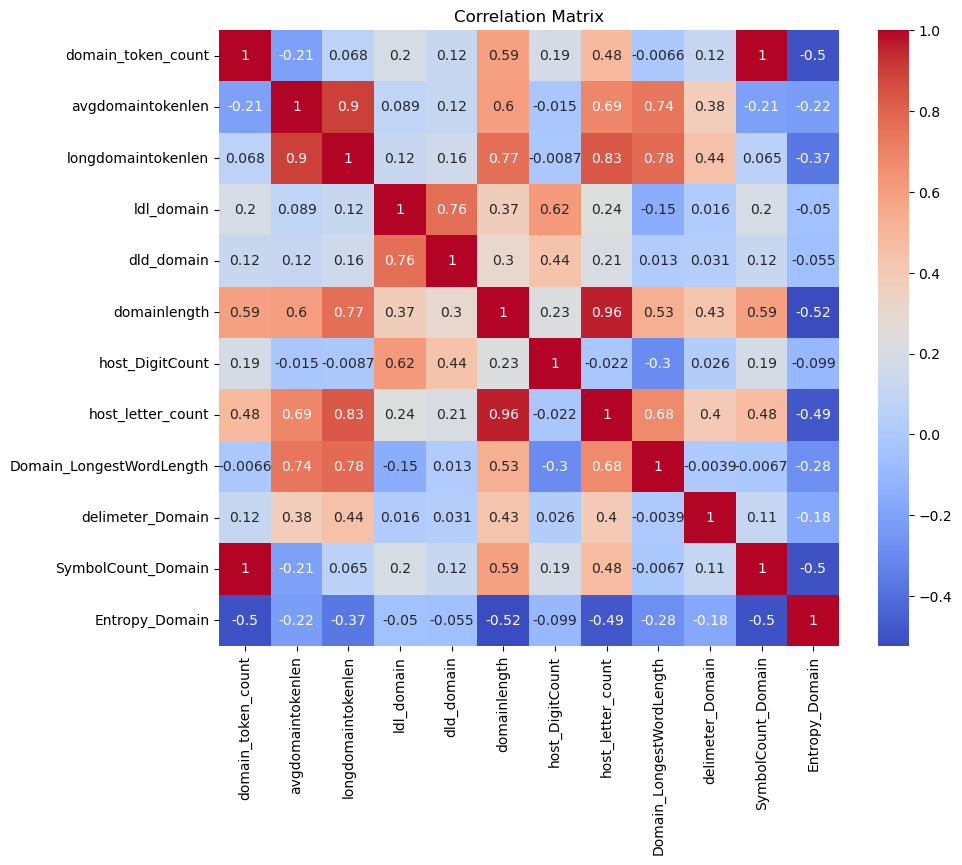

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [13]:
vif_col = [
    'domain_token_count', 'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

In [14]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[vif_col]

# 결측치 무한값 리리
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# 스케일링 (표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# VIF 
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])]

# 출력
print(vif_df.sort_values(by='VIF', ascending=False))

                     Feature         VIF
0         domain_token_count  389.735224
9         SymbolCount_Domain  387.363161
6          host_letter_count   15.319009
1          avgdomaintokenlen   12.992980
2         longdomaintokenlen   12.327037
7   Domain_LongestWordLength    8.653266
3                 ldl_domain    4.983512
8           delimeter_Domain    2.973490
4                 dld_domain    2.770994
5            host_DigitCount    2.592047
10            Entropy_Domain    1.638468


In [15]:
# 상관계수 계산
corr_matrix = X.corr()  # 피어슨 상관계수 기본
print(corr_matrix)

                          domain_token_count  avgdomaintokenlen  \
domain_token_count                  1.000000          -0.212984   
avgdomaintokenlen                  -0.212984           1.000000   
longdomaintokenlen                  0.068065           0.895807   
ldl_domain                          0.197289           0.089185   
dld_domain                          0.120969           0.116432   
host_DigitCount                     0.189512          -0.015315   
host_letter_count                   0.477180           0.687339   
Domain_LongestWordLength           -0.006629           0.739282   
delimeter_Domain                    0.118372           0.379142   
SymbolCount_Domain                  0.998674          -0.213186   
Entropy_Domain                     -0.503515          -0.220215   

                          longdomaintokenlen  ldl_domain  dld_domain  \
domain_token_count                  0.068065    0.197289    0.120969   
avgdomaintokenlen                   0.895807    0.0

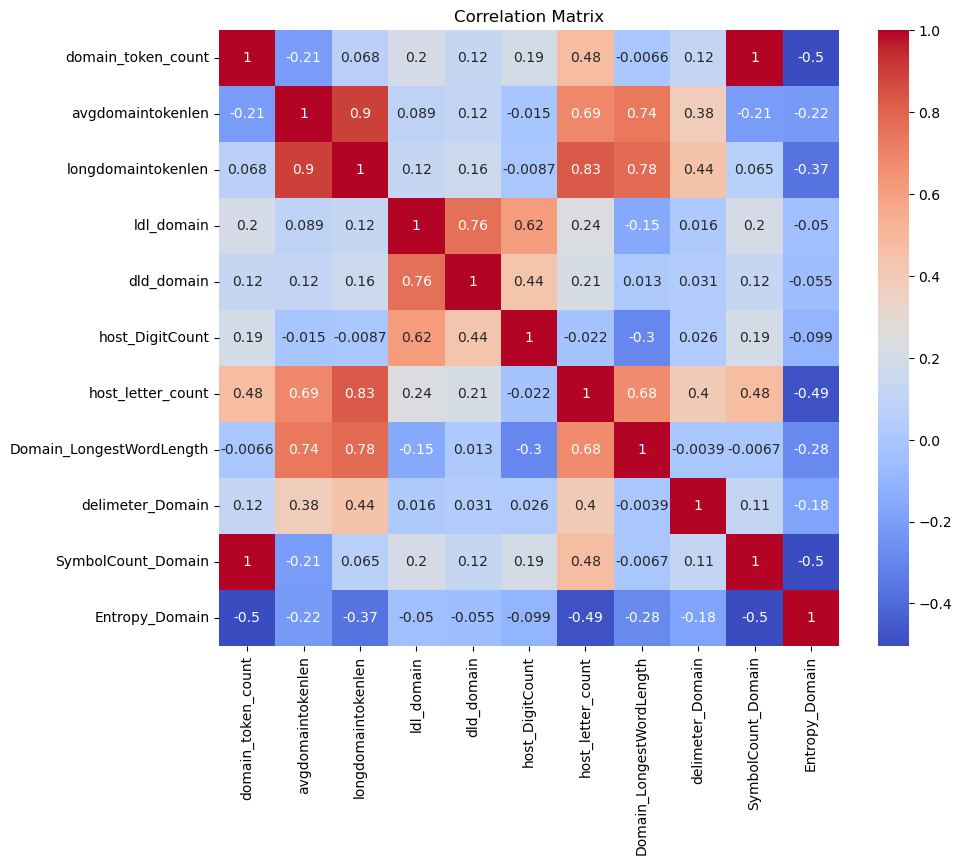

In [16]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [17]:
vif_col = [
    'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

In [18]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[vif_col]

# 결측치 무한값 리리
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# 스케일링 (표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# VIF 
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])]

# 출력
print(vif_df.sort_values(by='VIF', ascending=False))

                    Feature        VIF
5         host_letter_count  15.305802
0         avgdomaintokenlen  12.735634
1        longdomaintokenlen  12.222943
6  Domain_LongestWordLength   8.650037
8        SymbolCount_Domain   7.244643
2                ldl_domain   4.983181
7          delimeter_Domain   2.958513
3                dld_domain   2.769937
4           host_DigitCount   2.589749
9            Entropy_Domain   1.637842


In [19]:
# 상관계수 계산
corr_matrix = X.corr()  # 피어슨 상관계수 기본
print(corr_matrix)

                          avgdomaintokenlen  longdomaintokenlen  ldl_domain  \
avgdomaintokenlen                  1.000000            0.895807    0.089185   
longdomaintokenlen                 0.895807            1.000000    0.120057   
ldl_domain                         0.089185            0.120057    1.000000   
dld_domain                         0.116432            0.158417    0.763982   
host_DigitCount                   -0.015315           -0.008682    0.615290   
host_letter_count                  0.687339            0.829021    0.236331   
Domain_LongestWordLength           0.739282            0.779206   -0.151532   
delimeter_Domain                   0.379142            0.442622    0.015730   
SymbolCount_Domain                -0.213186            0.065447    0.197817   
Entropy_Domain                    -0.220215           -0.366726   -0.050124   

                          dld_domain  host_DigitCount  host_letter_count  \
avgdomaintokenlen           0.116432        -0.015315 

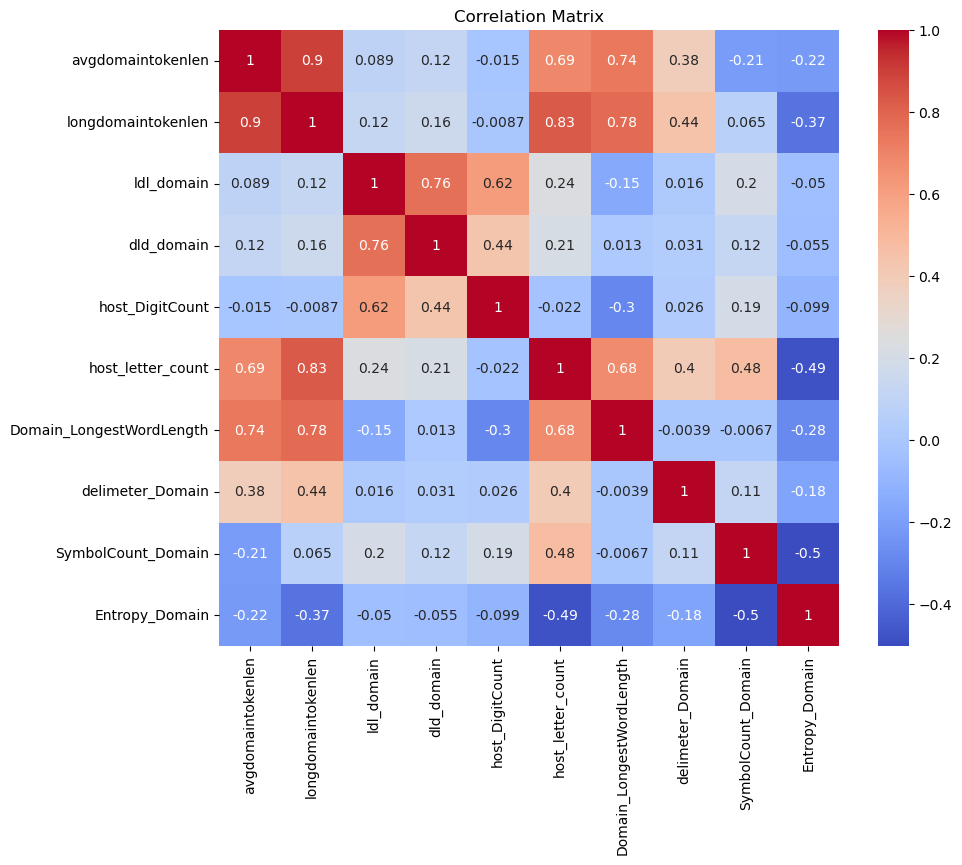

In [20]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [21]:
vif_col = [
    'avgdomaintokenlen', 'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

In [22]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[vif_col]

# 결측치 무한값 리리
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# 스케일링 (표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# VIF 
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])]

# 출력
print(vif_df.sort_values(by='VIF', ascending=False))

                    Feature        VIF
4         host_letter_count  14.570013
0         avgdomaintokenlen  11.292238
7        SymbolCount_Domain   7.221055
5  Domain_LongestWordLength   6.839736
1                ldl_domain   4.946190
2                dld_domain   2.763342
3           host_DigitCount   2.488688
6          delimeter_Domain   2.405985
8            Entropy_Domain   1.620765


In [23]:
# 상관계수 계산
corr_matrix = X.corr()  # 피어슨 상관계수 기본
print(corr_matrix)

                          avgdomaintokenlen  ldl_domain  dld_domain  \
avgdomaintokenlen                  1.000000    0.089185    0.116432   
ldl_domain                         0.089185    1.000000    0.763982   
dld_domain                         0.116432    0.763982    1.000000   
host_DigitCount                   -0.015315    0.615290    0.436147   
host_letter_count                  0.687339    0.236331    0.209219   
Domain_LongestWordLength           0.739282   -0.151532    0.013469   
delimeter_Domain                   0.379142    0.015730    0.031467   
SymbolCount_Domain                -0.213186    0.197817    0.121239   
Entropy_Domain                    -0.220215   -0.050124   -0.055322   

                          host_DigitCount  host_letter_count  \
avgdomaintokenlen               -0.015315           0.687339   
ldl_domain                       0.615290           0.236331   
dld_domain                       0.436147           0.209219   
host_DigitCount                  

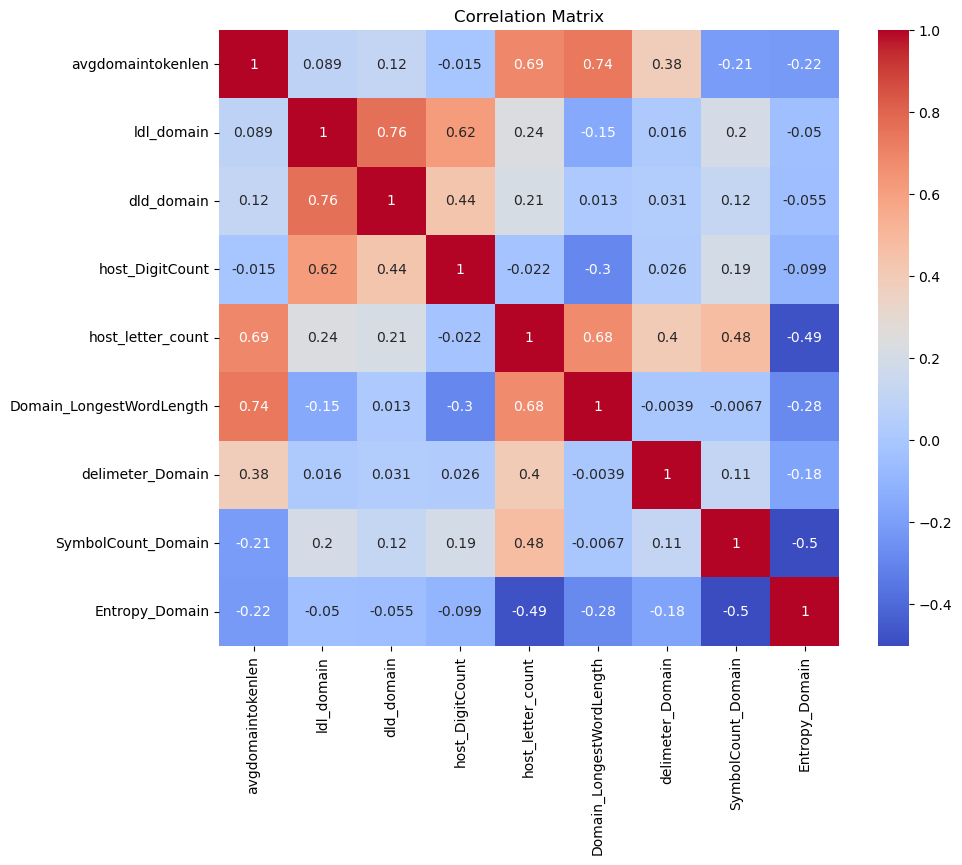

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [25]:
vif_col = [
    'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

In [26]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[vif_col]

# 결측치 무한값 리리
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# 스케일링 (표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# VIF 
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])]

# 출력
print(vif_df.sort_values(by='VIF', ascending=False))

                    Feature       VIF
3         host_letter_count  8.865823
4  Domain_LongestWordLength  5.774367
0                ldl_domain  4.945625
1                dld_domain  2.716417
6        SymbolCount_Domain  2.693311
5          delimeter_Domain  2.130082
2           host_DigitCount  1.871442
7            Entropy_Domain  1.579494


In [27]:
# 상관계수 계산
corr_matrix = X.corr()  # 피어슨 상관계수 기본
print(corr_matrix)

                          ldl_domain  dld_domain  host_DigitCount  \
ldl_domain                  1.000000    0.763982         0.615290   
dld_domain                  0.763982    1.000000         0.436147   
host_DigitCount             0.615290    0.436147         1.000000   
host_letter_count           0.236331    0.209219        -0.022170   
Domain_LongestWordLength   -0.151532    0.013469        -0.295048   
delimeter_Domain            0.015730    0.031467         0.026241   
SymbolCount_Domain          0.197817    0.121239         0.190034   
Entropy_Domain             -0.050124   -0.055322        -0.098729   

                          host_letter_count  Domain_LongestWordLength  \
ldl_domain                         0.236331                 -0.151532   
dld_domain                         0.209219                  0.013469   
host_DigitCount                   -0.022170                 -0.295048   
host_letter_count                  1.000000                  0.675603   
Domain_Longes

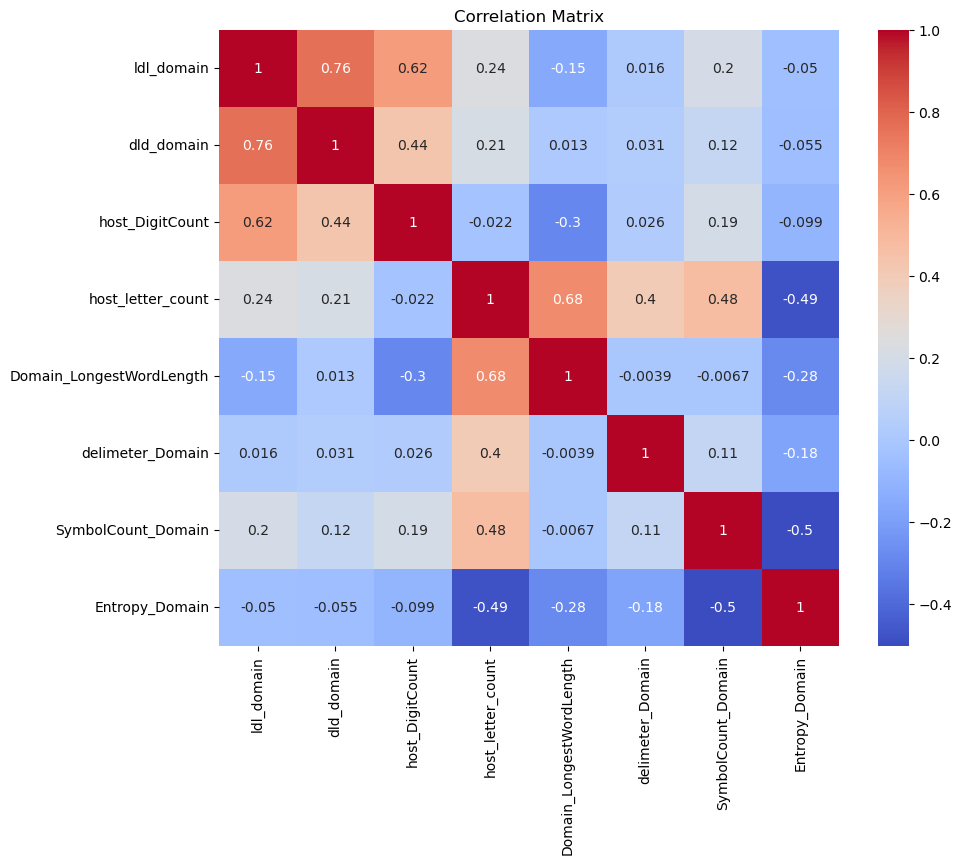

In [28]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [29]:
domain_col = [
     'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain',
    'URL_Type_obf_Type'
]

In [30]:
select_df = df[domain_col]

In [31]:
select_df['URL_Type_obf_Type'].value_counts()

URL_Type_obf_Type
Defacement    7930
benign        7781
phishing      7586
malware       6712
spam          6698
Name: count, dtype: int64

In [32]:
select_df.isnull().sum()

ldl_domain                  0
dld_domain                  0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [33]:
(select_df==-1).sum()

ldl_domain                  0
dld_domain                  0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [34]:
select_df = select_df[select_df['URL_Type_obf_Type'] != 'benign']

In [35]:
select_df['URL_Type_obf_Type'].value_counts()

URL_Type_obf_Type
Defacement    7930
phishing      7586
malware       6712
spam          6698
Name: count, dtype: int64

In [36]:
select_df.to_csv('for_modeling_3.csv', encoding='utf-8', index=False)

In [37]:
df = pd.read_csv('for_modeling_3.csv')

In [38]:
df

,ldl_domain,dld_domain,host_DigitCount,host_letter_count,Domain_LongestWordLength,delimeter_Domain,SymbolCount_Domain,Entropy_Domain,URL_Type_obf_Type
0,0,0,0,22,14,0,3,0.784493,Defacement
1,0,0,0,22,14,0,3,0.784493,Defacement
2,0,0,0,22,14,0,3,0.784493,Defacement
3,0,0,0,22,14,0,3,0.784493,Defacement
4,0,0,0,22,14,0,3,0.784493,Defacement
...,...,...,...,...,...,...,...,...,...
28921,0,0,0,23,12,0,3,0.791265,spam
28922,0,0,0,15,8,0,3,0.820010,spam
28923,0,0,0,20,16,0,2,0.801139,spam
28924,0,0,0,13,9,0,2,0.897617,spam
